<a href="https://colab.research.google.com/github/helloiamsuchi/AI-LAB/blob/main/Models_Applied_to_processed_stroke_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Index:
Different Machine Learning Models Applied to the Processed Stroke Dataset and do the Comparative Study among ML models

#Problem Statement:
You have the processed Stroke Dataset. Now apply any Five (05) Supervised Machine Learning Models to it (choose your own decided ML models), and also apply an ANN (Artificial Neural Network) as a Fifth model. Please show the following performance parameters: Precision, Recall, F1-Score, Accuracy, and AUC-ROC curve. Also show the Confusion Matrix of each model. Finally, evaluate the top 3 models for stroke risk prediction analysis and show the comparative results in the output.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    confusion_matrix, classification_report
)

In [4]:
uploaded = files.upload()

df = pd.read_csv('stroke_processed_5k.csv')

print("Dataset loaded successfully!")
print(df.head())

Saving stroke_processed_5k.csv to stroke_processed_5k.csv
Dataset loaded successfully!
   gender       age  hypertension  heart_disease  ever_married  work_type  \
0       1  1.051434             0              1             1          2   
1       0  0.786070             0              0             1          3   
2       1  1.626390             0              1             1          2   
3       0  0.255342             0              0             1          2   
4       0  1.582163             1              0             1          3   

   Residence_type  avg_glucose_level       bmi  smoking_status  stroke  
0               1           2.706375  1.005086               1       1  
1               0           2.121559 -0.098981               2       1  
2               0          -0.005028  0.472536               2       1  
3               1           1.437358  0.719327               3       1  
4               0           1.501184 -0.631531               2       1  


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStroke Distribution:")
print(df['stroke'].value_counts())

Dataset Shape: (5110, 11)

Column Names:
Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   int64  
 10  stroke             5110 non-null   int64  
dtypes: f

In [6]:
# Separate input features and target variable

X = df.drop('stroke', axis=1)
y = df['stroke']

# Scale the features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Features shape:", X_scaled.shape)
print("Target shape:", y.shape)

Features shape: (5110, 10)
Target shape: (5110,)


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (4088, 10)
Testing Features: (1022, 10)
Training Target: (4088,)
Testing Target: (1022,)


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

In [9]:
models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced',
        max_iter=1000
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42
    ),

    'SVM': SVC(
        probability=True,
        class_weight='balanced',
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'ANN': MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=500,
        random_state=42
    )
}

In [10]:
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "training completed!")

Logistic Regression training completed!
Random Forest training completed!
SVM training completed!
KNN training completed!
ANN training completed!


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [11]:
models['ANN'] = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    max_iter=1500,
    early_stopping=True,
    random_state=42
)

ann_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', models['ANN'])
])

ann_pipeline.fit(X_train, y_train)

trained_models['ANN'] = ann_pipeline

print("ANN retraining completed!")

ANN retraining completed!


In [12]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, zero_division=0
        ),
        'F1-Score': f1_score(
            y_test, y_pred, zero_division=0
        ),
        'AUC-ROC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC
Logistic Regression    0.7515     0.1408    0.80    0.2395   0.8387
      Random Forest    0.9501     0.0000    0.00    0.0000   0.7877
                SVM    0.7358     0.1181    0.68    0.2012   0.7856
                KNN    0.9481     0.2000    0.02    0.0364   0.6140
                ANN    0.9511     0.0000    0.00    0.0000   0.5410


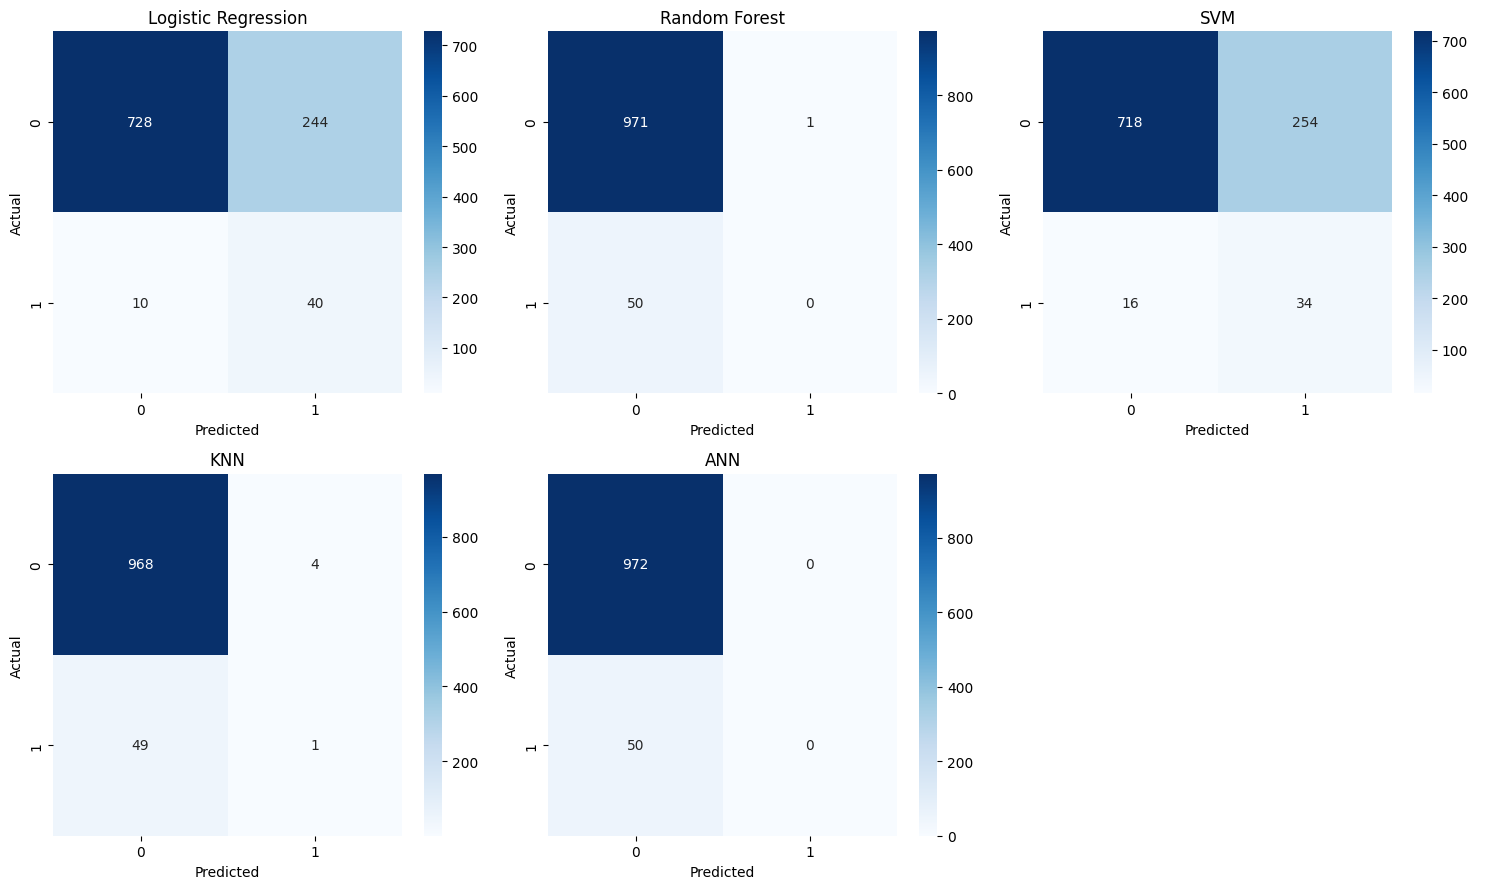

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (name, model) in zip(
    axes.flatten(), trained_models.items()
):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

axes.flatten()[-1].axis('off')

plt.tight_layout()
plt.show()

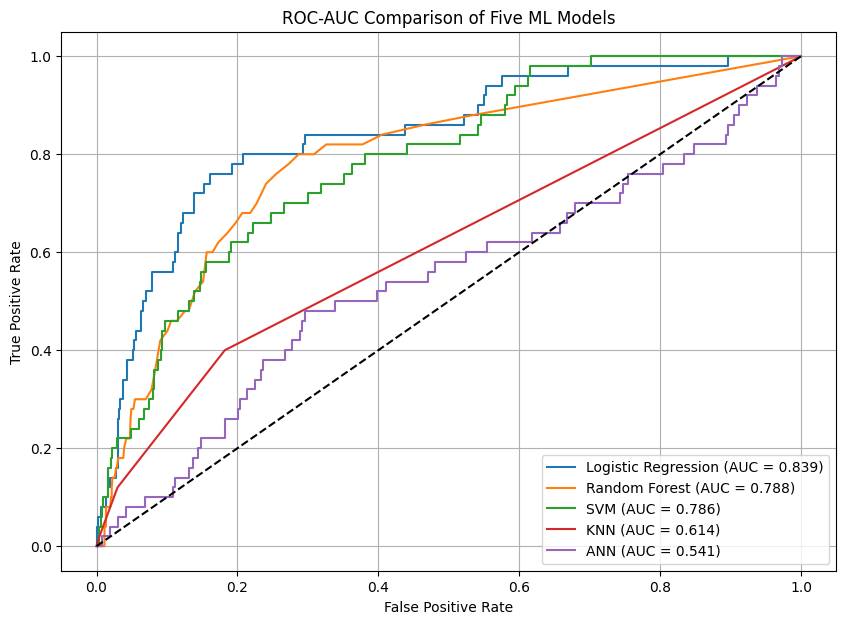

In [14]:
plt.figure(figsize=(10, 7))

for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Comparison of Five ML Models')

plt.legend()
plt.grid()
plt.show()

In [15]:
top_3 = results_df.sort_values(
    by='AUC-ROC',
    ascending=False
).head(3)

print(top_3.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC
Logistic Regression    0.7515     0.1408    0.80    0.2395   0.8387
      Random Forest    0.9501     0.0000    0.00    0.0000   0.7877
                SVM    0.7358     0.1181    0.68    0.2012   0.7856


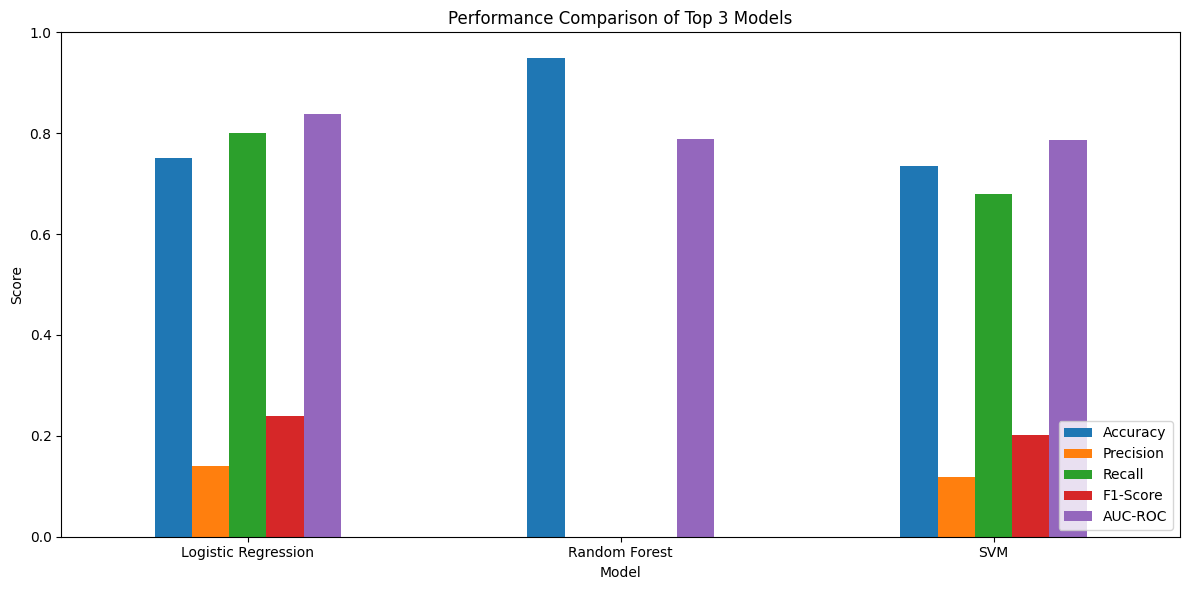

In [16]:
top_3.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Performance Comparison of Top 3 Models')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Conclusion

In this experiment, five supervised machine learning models—Logistic Regression, Random Forest, Support Vector Machine (SVM), K-Nearest Neighbors (KNN), and Artificial Neural Network (ANN)—were trained and evaluated using the processed Stroke Dataset.

The comparative study showed that Logistic Regression performed best overall, achieving an AUC-ROC score of 0.8387 and a recall of 80%. SVM also showed reasonable performance with 68% recall and an AUC-ROC of 0.7856. Random Forest achieved the highest accuracy of 95.01%, but failed to identify any actual stroke cases at the default classification threshold. KNN and ANN also showed poor stroke detection performance.

The dataset was highly imbalanced, with approximately 95% non-stroke cases and 5% stroke cases. Therefore, accuracy alone was not a reliable measure of model performance. Recall, F1-score, confusion matrices, and AUC-ROC were also important for comparison.

Overall, Logistic Regression was the strongest model in this experiment. However, further improvements through class-imbalance handling, hyperparameter tuning, and classification threshold adjustment may improve stroke detection performance.